In [6]:
import os
import torch
from torchvision import datasets

# 1. Check GPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

# 2. Copy dataset from Google Drive to local Colab disk (prevents Epoch 0 hang)
DRIVE_DIR = "/content/drive/MyDrive/ml_prject/data/leaf_dissease"
LOCAL_DIR = "/content/leaf_dissease"

if not os.path.exists(LOCAL_DIR):
    print("Copying dataset to local Colab disk (takes ~1–2 mins)...")
    !cp -r "{DRIVE_DIR}" "{LOCAL_DIR}"
    print("Copy complete!")
else:
    print("Local dataset already exists.")

# 3. Check classes and image counts
full_dataset = datasets.ImageFolder(LOCAL_DIR)
print(f"\nTotal images: {len(full_dataset)}")
print(f"Classes: {full_dataset.classes}")
print(f"Class mapping: {full_dataset.class_to_idx}\n")

for class_name in sorted(os.listdir(LOCAL_DIR)):
    class_path = os.path.join(LOCAL_DIR, class_name)
    if os.path.isdir(class_path):
        print(f"  {class_name}: {len(os.listdir(class_path))} images")

Using device: cuda
GPU Name: Tesla T4
Copying dataset to local Colab disk (takes ~1–2 mins)...
Copy complete!

Total images: 12395
Classes: ['Common Rust', 'Corn Leaf Blight', 'Gray Leaf Spot', 'Healthy', 'Insects damage']
Class mapping: {'Common Rust': 0, 'Corn Leaf Blight': 1, 'Gray Leaf Spot': 2, 'Healthy': 3, 'Insects damage': 4}

  Common Rust: 3024 images
  Corn Leaf Blight: 3338 images
  Gray Leaf Spot: 2395 images
  Healthy: 1859 images
  Insects damage: 1779 images


In [7]:
import numpy as np
from sklearn.model_selection import train_test_split

targets = np.array(full_dataset.targets)
indices = np.arange(len(full_dataset))

# First split: 80% Train, 20% Temp
train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.20,
    stratify=targets,
    random_state=42
)

# Second split: 10% Val, 10% Test
temp_targets = targets[temp_indices]
val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    stratify=temp_targets,
    random_state=42
)

print("Split Completed (80/10/10):")
print(f"  Train size: {len(train_indices)} ({len(train_indices)/len(full_dataset)*100:.1f}%)")
print(f"  Val size:   {len(val_indices)} ({len(val_indices)/len(full_dataset)*100:.1f}%)")
print(f"  Test size:  {len(test_indices)} ({len(test_indices)/len(full_dataset)*100:.1f}%)")

Split Completed (80/10/10):
  Train size: 9916 (80.0%)
  Val size:   1239 (10.0%)
  Test size:  1240 (10.0%)


In [8]:
import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# 1. Get targets/labels for stratification
targets = np.array(full_dataset.targets)
indices = np.arange(len(full_dataset))

# 2. First split: 80% train, 20% temp (which will be split into val/test)
train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.20,
    stratify=targets,
    random_state=42
)

# Get targets of temp split to stratify the second split
temp_targets = targets[temp_indices]

# 3. Second split: split the 20% temp set equally into validation (10%) and test (10%)
val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    stratify=temp_targets,
    random_state=42
)

print(f"Split Completed (80/10/10):")
print(f"Train size: {len(train_indices)} ({len(train_indices)/len(full_dataset)*100:.1f}%)")
print(f"Val size:   {len(val_indices)} ({len(val_indices)/len(full_dataset)*100:.1f}%)")
print(f"Test size:  {len(test_indices)} ({len(test_indices)/len(full_dataset)*100:.1f}%)")

Split Completed (80/10/10):
Train size: 9916 (80.0%)
Val size:   1239 (10.0%)
Test size:  1240 (10.0%)


In [9]:
import copy
from torch.utils.data import DataLoader, Subset
from torchvision.transforms import v2

BATCH_SIZE = 32

# Train augmentation
train_transforms = v2.Compose([
    v2.RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0)),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomVerticalFlip(p=0.5),
    v2.RandomRotation(degrees=30),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Clean preprocessing for Val & Test
eval_transforms = v2.Compose([
    v2.Resize(size=(256, 256)),
    v2.CenterCrop(size=(224, 224)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Apply transforms to independent copies
train_base = copy.deepcopy(full_dataset)
val_base   = copy.deepcopy(full_dataset)
test_base  = copy.deepcopy(full_dataset)

train_base.transform = train_transforms
val_base.transform   = eval_transforms
test_base.transform  = eval_transforms

train_subset = Subset(train_base, train_indices)
val_subset   = Subset(val_base, val_indices)
test_subset  = Subset(test_base, test_indices)

# Fast local-disk DataLoaders
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_subset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_subset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"DataLoaders ready! Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}")

DataLoaders ready! Train batches: 310, Val batches: 39, Test batches: 39


In [ ]:
import torch.nn as nn
from torchvision import models
from tqdm import tqdm

NUM_CLASSES = 5
EPOCHS = 30

# 1. Build MobileNetV3-Large
def build_mobilenet_v3_large(num_classes=5, freeze_backbone=False):
    weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2
    model = models.mobilenet_v3_large(weights=weights)

    if freeze_backbone:
        for param in model.features.parameters():
            param.requires_grad = False

    model.classifier[2] = nn.Dropout(p=0.3, inplace=True)
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model

model = build_mobilenet_v3_large(num_classes=NUM_CLASSES, freeze_backbone=False).to(DEVICE)

# 2. Loss, Optimizer, Scheduler, Mixed Precision
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW([
    {"params": model.features.parameters(), "lr": 1e-4},
    {"params": model.classifier.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
use_amp = (DEVICE.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

# 3. Training & Validation Loop
best_val_acc = 0.0
history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}

print("Starting Training with MobileNetV3-Large...")
for epoch in range(EPOCHS):
    # --- TRAIN ---
    model.train()
    train_loss, train_correct = 0.0, 0

    pbar = tqdm(train_loader, desc=f"Epoch [{epoch+1:02d}/{EPOCHS}]", leave=False)
    for images, labels in pbar:
        images, labels = images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()

        with torch.amp.autocast("cuda", enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    scheduler.step()

    # --- VALIDATE ---
    model.eval()
    val_loss, val_correct = 0.0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    train_acc = 100.0 * train_correct / len(train_subset)
    val_acc   = 100.0 * val_correct / len(val_subset)
    avg_train_loss = train_loss / len(train_subset)
    avg_val_loss   = val_loss / len(val_subset)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | Train Loss: {avg_train_loss:.4f} | Train Acc: {train_acc:.2f}% | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_mobilenetv3_large_corn.pth")
        print(f"  --> Saved new best model (Val Acc: {best_val_acc:.2f}%)")

Starting Training with MobileNetV3-Large...


Epoch [01/30] | Train Loss: 0.5473 | Train Acc: 93.53% | Val Loss: 0.4736 | Val Acc: 96.69%
  --> Saved new best model (Val Acc: 96.69%)


Epoch [02/30] | Train Loss: 0.4604 | Train Acc: 97.49% | Val Loss: 0.4554 | Val Acc: 96.69%


Epoch [03/30] | Train Loss: 0.4348 | Train Acc: 98.41% | Val Loss: 0.4247 | Val Acc: 98.55%
  --> Saved new best model (Val Acc: 98.55%)


Epoch [04/30] | Train Loss: 0.4214 | Train Acc: 98.99% | Val Loss: 0.4295 | Val Acc: 97.98%


Epoch [05/30] | Train Loss: 0.4169 | Train Acc: 99.15% | Val Loss: 0.4196 | Val Acc: 98.71%
  --> Saved new best model (Val Acc: 98.71%)


... (21 outputs left out)

Epoch [27/30] | Train Loss: 0.3922 | Train Acc: 99.95% | Val Loss: 0.3922 | Val Acc: 99.92%


Epoch [28/30] | Train Loss: 0.3917 | Train Acc: 99.96% | Val Loss: 0.3923 | Val Acc: 99.92%


Epoch [29/30] | Train Loss: 0.3917 | Train Acc: 99.95% | Val Loss: 0.3923 | Val Acc: 99.92%


Epoch [30/30] | Train Loss: 0.3920 | Train Acc: 99.95% | Val Loss: 0.3926 | Val Acc: 99.92%


Test Accuracy: 99.84% (1238/1240 correct, 2 incorrect)

Classification Report on Test Dataset:
                  precision    recall  f1-score   support

     Common Rust     1.0000    1.0000    1.0000       303
Corn Leaf Blight     0.9940    1.0000    0.9970       334
  Gray Leaf Spot     1.0000    0.9916    0.9958       239
         Healthy     1.0000    1.0000    1.0000       186
  Insects damage     1.0000    1.0000    1.0000       178

        accuracy                         0.9984      1240
       macro avg     0.9988    0.9983    0.9986      1240
    weighted avg     0.9984    0.9984    0.9984      1240



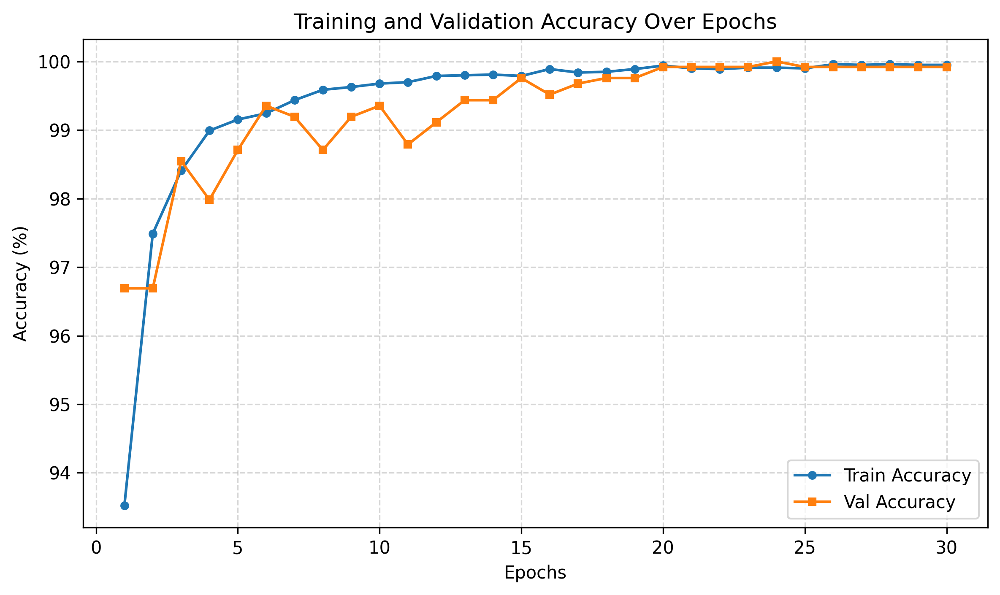

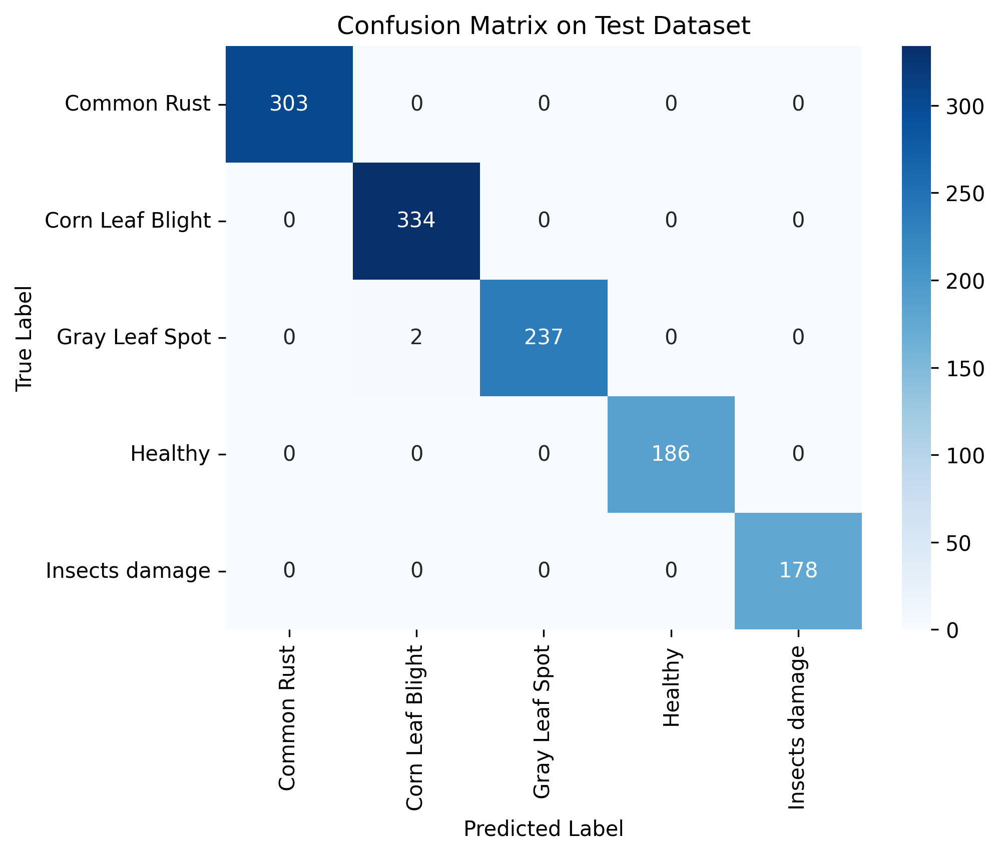

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load the best saved checkpoint
model.load_state_dict(torch.load("best_mobilenetv3_large_corn.pth", map_location=DEVICE))
model.eval()

all_preds = []
all_labels = []

# 2. Run inference on the unseen test set
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 3. Exact Accuracy & Classification Report
correct = (all_preds == all_labels).sum()
total = len(all_labels)
exact_acc = 100.0 * correct / total

print(f"Test Accuracy: {exact_acc:.2f}% ({correct}/{total} correct, {total - correct} incorrect)\n")
print("Classification Report on Test Dataset:")
print(classification_report(all_labels, all_preds, target_names=full_dataset.classes, digits=4))

# 4. Plot & Save Training vs. Validation Accuracy Curve
epochs_range = range(1, len(history["train_acc"]) + 1)
plt.figure(figsize=(8, 4.8), dpi=300)
plt.plot(epochs_range, history["train_acc"], marker="o", markersize=4, label="Train Accuracy")
plt.plot(epochs_range, history["val_acc"], marker="s", markersize=4, label="Val Accuracy")
plt.title("Training and Validation Accuracy Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("accuracy_curve_80_10_10.png", dpi=300)
plt.show()

# 5. Plot & Save Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 5.8), dpi=300)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=full_dataset.classes,
    yticklabels=full_dataset.classes
)
plt.title("Confusion Matrix on Test Dataset")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("confusion_matrix_80_10_10.png", dpi=300)
plt.show()

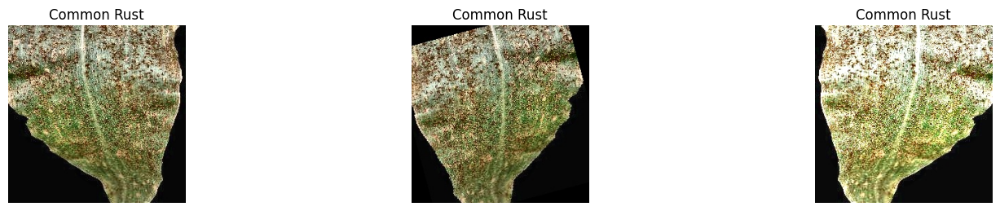

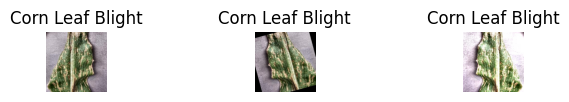

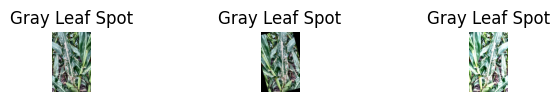

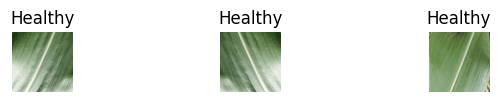

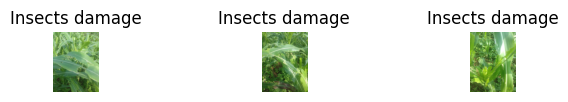

In [ ]:
from IPython.core.display import Image
import os
import matplotlib.pyplot as plt
from PIL import Image

NUM_IMAGES = 3
classes = sorted(os.listdir(DATA_DIR))
plt.figure(figsize=(15,12))
plot_index = 1
for class_name in classes:
  class_path = os.path.join(DATA_DIR, class_name)

  if not os.path.isdir(class_path):
    continue

  image_files = [
      f for f in os.listdir(class_path)
      if f.lower().endswith(('.jpg','jpef','.png','.bmp')) ]

  for image_file in image_files[:NUM_IMAGES]:
    images_path = os.path.join(class_path, image_file)

    image = Image.open(images_path)

    plt.subplot(len(classes), NUM_IMAGES, plot_index)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")
    plot_index +=1

  plt.tight_layout()
  plt.show()


In [5]:
# Install required dependencies for ONNX export in Colab
!pip install -q onnx onnxscript

import torch
import torch.nn as nn
from torchvision import models

# 1. Rebuild the MobileNetV3 architecture
def build_mobilenet_v3_large(num_classes=5):
    # Using weights=None as we are about to load our own trained weights
    model = models.mobilenet_v3_large(weights=None)
    model.classifier[2] = nn.Dropout(p=0.3, inplace=True)
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model

# 2. Instantiate and load trained weights
model = build_mobilenet_v3_large(num_classes=5)
model.load_state_dict(torch.load("best_mobilenetv3_large_corn.pth", map_location="cpu"))
model.eval()

# 3. Export to ONNX
dummy_input = torch.randn(1, 3, 224, 224)

torch.onnx.export(
    model,
    dummy_input,
    "mobilenetv3_corn.onnx",
    input_names=["input"],
    output_names=["output"],
    opset_version=18
)

W1125 07:57:41.626000 354 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 13 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


ONNXProgram(
    model=
        <
            ir_version=10,
            opset_imports={'': 18},
            producer_name='pytorch',
            producer_version='2.14.1+cu130',
            domain=None,
            model_version=None,
        >
        graph(
            name=main_graph,
            inputs=(
                %"input"<FLOAT,[1,3,224,224]>
            ),
            outputs=(
                %"output"<FLOAT,[1,5]>
            ),
            initializers=(
                %"features.0.0.weight"<FLOAT,[16,3,3,3]>{Tensor(...)},
                %"features.1.block.0.0.weight"<FLOAT,[16,1,3,3]>{Tensor(...)},
                %"features.1.block.1.0.weight"<FLOAT,[16,16,1,1]>{Tensor(...)},
                %"features.2.block.1.0.weight"<FLOAT,[64,1,3,3]>{Tensor(...)},
                %"features.3.block.1.0.weight"<FLOAT,[72,1,3,3]>{Tensor(...)},
                %"features.4.block.2.fc1.bias"<FLOAT,[24]>{TorchTensor(...)},
                %"features.4.block.2.fc2.bias"<FLOAT,[72]>{

Testing ONNX Model with file: /content/leaf_dissease/Healthy/c1b92121-7167-4380-905c-ba816d19c11d___R.S_HL 0598 copy 3.jpg (True Class: Healthy)


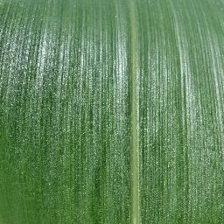


ONNX Runtime Inference Result:
-> Predicted Class: Healthy (Index: 3)
-> Model Logits: [-0.6413559  -0.6370486  -0.84175235  3.2468731  -0.78655636]


In [11]:
# Install ONNX Runtime for inference
!pip install -q onnxruntime

import os
import numpy as np
import onnxruntime as ort
from PIL import Image
import torchvision.transforms as transforms

# 1. Load ONNX model using ONNX Runtime
onnx_model_path = "/content/mobilenetv3_corn.onnx"
ort_session = ort.InferenceSession(onnx_model_path)

# Get class names from original dataset
class_names = ['Common Rust', 'Corn Leaf Blight', 'Gray Leaf Spot', 'Healthy', 'Insects damage']

# 2. Prepare a sample image from the local dataset
# Find a sample image from one of the folders to test with
sample_folder = "/content/leaf_dissease/Healthy"
sample_images = [f for f in os.listdir(sample_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

if len(sample_images) > 0:
    test_image_path = os.path.join(sample_folder, sample_images[0])
    print(f"Testing ONNX Model with file: {test_image_path} (True Class: Healthy)")

    # 3. Preprocess image identical to eval_transforms
    # Resize(256) -> CenterCrop(224) -> ToTensor & Normalization
    img = Image.open(test_image_path).convert('RGB')
    preprocess = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    input_tensor = preprocess(img).unsqueeze(0).numpy() # Convert to batch of size 1 numpy array

    # 4. Run inference via ONNX Runtime
    ort_inputs = {ort_session.get_inputs()[0].name: input_tensor}
    ort_outs = ort_session.run(None, ort_inputs)

    logits = ort_outs[0]
    predicted_class_idx = np.argmax(logits, axis=1)[0]
    predicted_class = class_names[predicted_class_idx]

    # Display the results
    display(img.resize((224, 224)))
    print(f"\nONNX Runtime Inference Result:")
    print(f"-> Predicted Class: {predicted_class} (Index: {predicted_class_idx})")
    print(f"-> Model Logits: {logits[0]}")
else:
    print("Could not locate sample images under /content/leaf_dissease/Healthy to run test.")

ONNX Model Test Accuracy: 99.84% (1238/1240 correct, 2 incorrect)

Classification Report on Test Dataset (ONNX):
                  precision    recall  f1-score   support

     Common Rust     1.0000    1.0000    1.0000       303
Corn Leaf Blight     0.9940    1.0000    0.9970       334
  Gray Leaf Spot     1.0000    0.9916    0.9958       239
         Healthy     1.0000    1.0000    1.0000       186
  Insects damage     1.0000    1.0000    1.0000       178

        accuracy                         0.9984      1240
       macro avg     0.9988    0.9983    0.9986      1240
    weighted avg     0.9984    0.9984    0.9984      1240



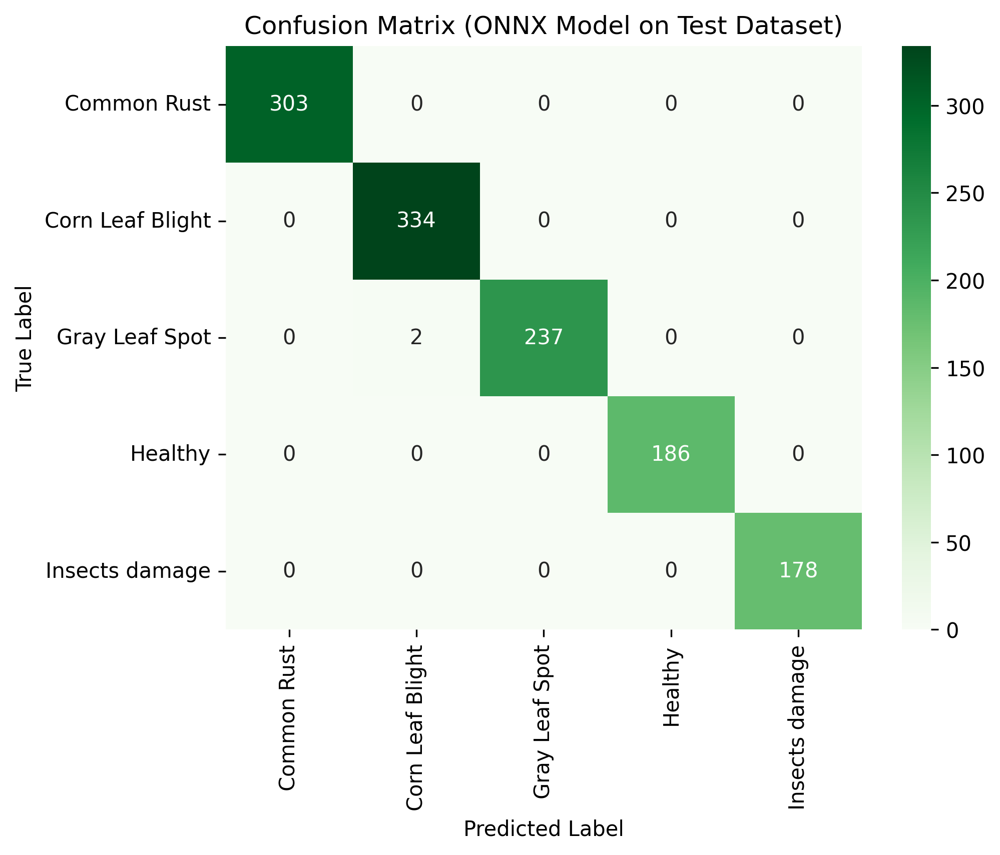

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import onnxruntime as ort

# 1. Initialize ONNX Runtime session
ort_session = ort.InferenceSession("/content/mobilenetv3_corn.onnx")
input_name = ort_session.get_inputs()[0].name

all_preds = []
all_labels = []

# 2. Run inference on the unseen test set using the ONNX model
for images, labels in test_loader:
    # Since the ONNX model expects batch size = 1, we iterate through the batch
    for i in range(images.size(0)):
        # Extract single image, convert to numpy, add batch dimension [1, 3, 224, 224]
        input_tensor = images[i].unsqueeze(0).numpy()

        # Run inference
        ort_inputs = {input_name: input_tensor}
        ort_outs = ort_session.run(None, ort_inputs)

        pred = np.argmax(ort_outs[0], axis=1)[0]
        all_preds.append(pred)
        all_labels.append(labels[i].item())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 3. Exact Accuracy & Classification Report
correct = (all_preds == all_labels).sum()
total = len(all_labels)
exact_acc = 100.0 * correct / total

print(f"ONNX Model Test Accuracy: {exact_acc:.2f}% ({correct}/{total} correct, {total - correct} incorrect)\n")
print("Classification Report on Test Dataset (ONNX):")
print(classification_report(all_labels, all_preds, target_names=full_dataset.classes, digits=4))

# 4. Plot & Save Confusion Matrix for ONNX model
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 5.8), dpi=300)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=full_dataset.classes,
    yticklabels=full_dataset.classes
)
plt.title("Confusion Matrix (ONNX Model on Test Dataset)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("onnx_confusion_matrix.png", dpi=300)
plt.show()

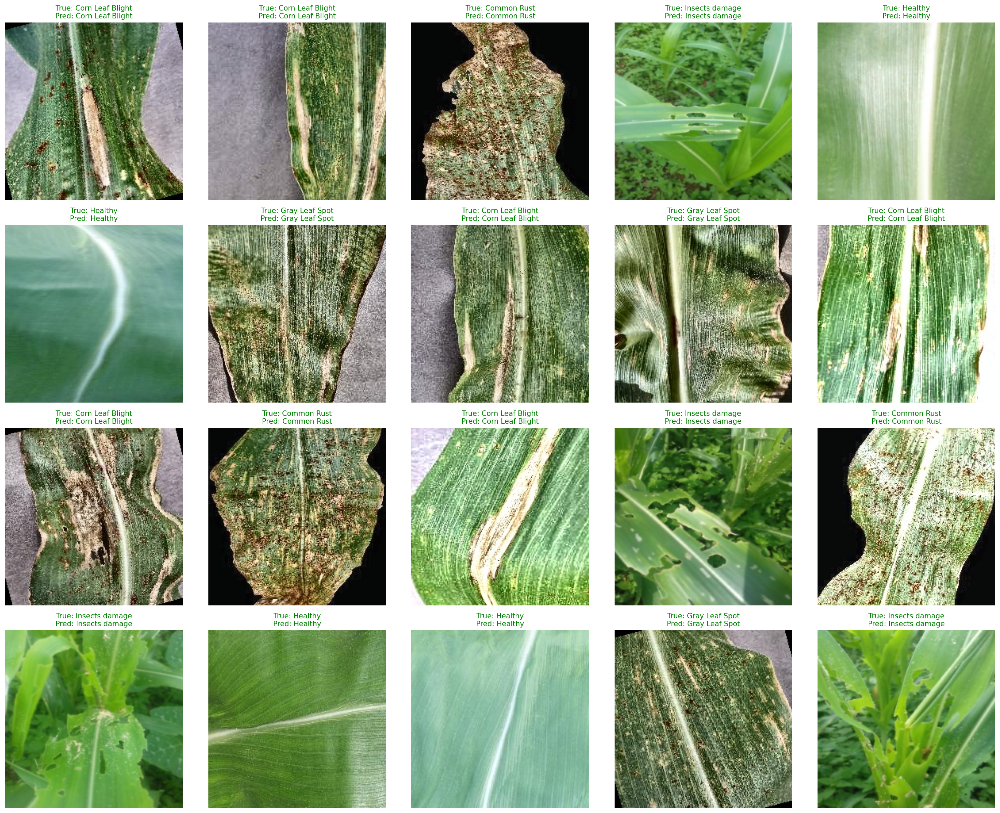

In [14]:
import random
import matplotlib.pyplot as plt

# 1. Select 20 random indices from the test dataset
random.seed(42)  # For reproducibility
sample_indices = random.sample(range(len(test_subset)), 20)

# 2. Set up visualization grid
fig, axes = plt.subplots(4, 5, figsize=(20, 16), dpi=150)
axes = axes.flatten()

# Class names mapped back
class_names = full_dataset.classes

# 3. Retrieve, predict, and plot each sample
for idx, sample_idx in enumerate(sample_indices):
    # Get original image (tensor) and true label
    img_tensor, true_label_idx = test_subset[sample_idx]

    # Prepare image tensor for ONNX inference [1, 3, 224, 224]
    input_tensor = img_tensor.unsqueeze(0).numpy()

    # Run ONNX inference
    ort_inputs = {input_name: input_tensor}
    ort_outs = ort_session.run(None, ort_inputs)
    pred_label_idx = np.argmax(ort_outs[0], axis=1)[0]

    # Convert tensor back to printable format (Denormalize and change shape to HWC)
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    np_img = img_tensor.permute(1, 2, 0).numpy()
    np_img = np_img * std + mean  # Denormalize
    np_img = np.clip(np_img, 0, 1)  # Clip to valid [0, 1] range

    # Plot image
    ax = axes[idx]
    ax.imshow(np_img)
    ax.axis("off")

    # Title coloring: Green if correct, Red if incorrect
    true_class = class_names[true_label_idx]
    pred_class = class_names[pred_label_idx]
    title_color = "green" if true_label_idx == pred_label_idx else "red"

    ax.set_title(f"True: {true_class}\nPred: {pred_class}", color=title_color, fontsize=10)

plt.tight_layout()
plt.show()